<a href="https://colab.research.google.com/github/Arif-Khan001/SKU_Slotting-Optimization/blob/main/SKU_Slotting_Optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/fc_slotting_dataset.csv', parse_dates=["order_date"])
df.head()

,order_line_id,order_id,order_date,sku_id,sku_name,category,unit_weight_kg,qty_picked,current_location_id,aisle_x,bay_y,dock_x,dock_y
0,1,ORD-10000,2024-01-01,SKU-0023,Cooking Oil 1L,Grocery,1.00,1,A03-B09,3,9,0,0
1,2,ORD-10000,2024-01-02,SKU-0025,Protein Bar Box (12ct),Grocery,0.60,2,A02-B01,2,1,0,0
2,3,ORD-10001,2024-01-02,SKU-0023,Cooking Oil 1L,Grocery,1.00,1,A03-B09,3,9,0,0
3,4,ORD-10001,2024-01-03,SKU-0005,Portable Power Bank 10000mAh,Electronics,0.22,4,A06-B04,6,4,0,0
4,5,ORD-10002,2024-01-03,SKU-0005,Portable Power Bank 10000mAh,Electronics,0.22,4,A06-B04,6,4,0,0


In [ ]:
print("Date range:", df["order_date"].min().date(), "to", df["order_date"].max().date())
print("\nUnique SKUs:", df["sku_id"].nunique())
print("Unique orders:", df["order_id"].nunique())

Date range: 2024-01-01 to 2024-03-30

Unique SKUs: 32
Unique orders: 100


In [ ]:
print("Missing values:\n", df.isna().sum())
print("\nCategory mix:")


Missing values:
 order_line_id          0
order_id               0
order_date             0
sku_id                 0
sku_name               0
category               0
unit_weight_kg         0
qty_picked             0
current_location_id    0
aisle_x                0
bay_y                  0
dock_x                 0
dock_y                 0
dtype: int64

Category mix:


In [ ]:
print(df.drop_duplicates("sku_id")["category"].value_counts())

category
Grocery                    6
Electronics Accessories    5
Electronics                4
Apparel                    4
Home & Kitchen             4
Personal Care              3
Stationery                 3
Sports & Fitness           2
Apparel Accessories        1
Name: count, dtype: int64


In [ ]:
#Build SKU Master
sku_cols = ["sku_id", "sku_name", "category", "unit_weight_kg",
            "current_location_id", "aisle_x", "bay_y", "dock_x", "dock_y"]

In [ ]:
sku_master = df[sku_cols].drop_duplicates(subset="sku_id").reset_index(drop=True)
print(sku_master.shape)
sku_master.head()

(32, 9)


,sku_id,sku_name,category,unit_weight_kg,current_location_id,aisle_x,bay_y,dock_x,dock_y
0,SKU-0023,Cooking Oil 1L,Grocery,1.00,A03-B09,3,9,0,0
1,SKU-0025,Protein Bar Box (12ct),Grocery,0.60,A02-B01,2,1,0,0
2,SKU-0005,Portable Power Bank 10000mAh,Electronics,0.22,A06-B04,6,4,0,0
3,SKU-0004,Smartwatch Fitness Band,Electronics,0.06,A05-B07,5,7,0,0
4,SKU-0036,Face Moisturizer Cream 100g,Personal Care,0.15,A06-B06,6,6,0,0


In [ ]:
pick_freq = (
    df.groupby("sku_id")
      .agg(pick_lines=("order_line_id", "count"),
           units_picked=("qty_picked", "sum"))
      .reset_index()
)

In [ ]:

sku_master = sku_master.merge(pick_freq, on="sku_id", how="left")
sku_master[["pick_lines", "units_picked"]] = sku_master[["pick_lines", "units_picked"]].fillna(0)

In [ ]:
sku_master = sku_master.sort_values("pick_lines", ascending=False).reset_index(drop=True)
sku_master.head(10)

,sku_id,sku_name,category,unit_weight_kg,current_location_id,aisle_x,bay_y,dock_x,dock_y,pick_lines,units_picked
0,SKU-0025,Protein Bar Box (12ct),Grocery,0.60,A02-B01,2,1,0,0,61,156
1,SKU-0023,Cooking Oil 1L,Grocery,1.00,A03-B09,3,9,0,0,43,116
2,SKU-0005,Portable Power Bank 10000mAh,Electronics,0.22,A06-B04,6,4,0,0,18,45
3,SKU-0041,Yoga Mat 6mm,Sports & Fitness,1.00,A04-B07,4,7,0,0,18,45
4,SKU-0026,Instant Coffee 200g,Grocery,0.22,A01-B09,1,9,0,0,6,14
5,SKU-0027,Men's Cotton T-Shirt,Apparel,0.20,A07-B00,7,0,0,0,5,15
6,SKU-0019,Instant Noodles Pack (12ct),Grocery,1.20,A07-B02,7,2,0,0,5,11
7,SKU-0004,Smartwatch Fitness Band,Electronics,0.06,A05-B07,5,7,0,0,4,8
8,SKU-0048,Desk Organizer Tray,Stationery,0.50,A05-B02,5,2,0,0,4,8
9,SKU-0008,Mechanical Keyboard,Electronics Accessories,0.85,A02-B02,2,2,0,0,3,7


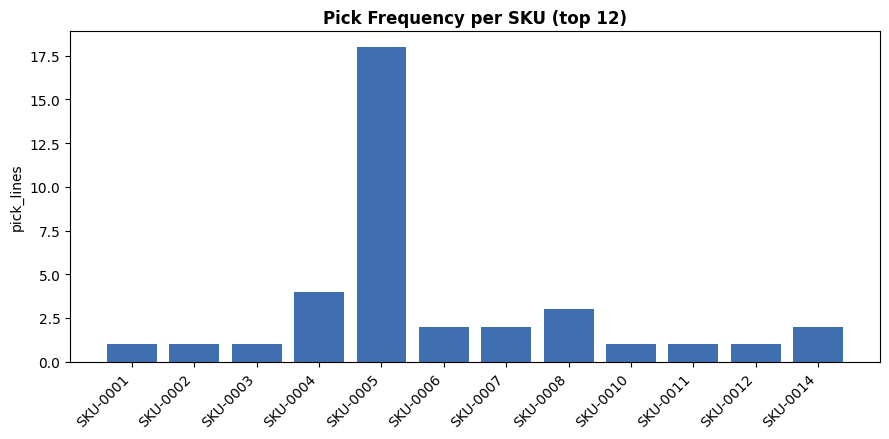

In [ ]:
import matplotlib.pyplot as plt

top = sku_master.head(12)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(top['sku_id'], top['pick_lines'], color='#3f6fb0')
ax.set_title('Pick Frequency per SKU (top 12)', fontweight='bold')
ax.set_ylabel('pick_lines')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
total_lines = sku_master["pick_lines"].sum()
sku_master["cum_pick_lines"] = sku_master["pick_lines"].cumsum()
sku_master["cum_pct"] = sku_master["cum_pick_lines"] / total_lines


In [ ]:
def classify(cum_pct):
    if cum_pct <= 0.80:
        return "A"
    elif cum_pct <= 0.95:
        return "B"
    return "C"

In [ ]:
sku_master["abc_class"] = sku_master["cum_pct"].apply(classify)

print(sku_master["abc_class"].value_counts())
print("\nPick-line share by class:")
print(sku_master.groupby("abc_class")["pick_lines"].sum() / total_lines)

abc_class
B    14
C    10
A     8
Name: count, dtype: int64

Pick-line share by class:
abc_class
A    0.80
B    0.15
C    0.05
Name: pick_lines, dtype: float64


In [ ]:
sku_master["before_dist_to_dock"] = (
    (sku_master["aisle_x"] - sku_master["dock_x"]).abs()
    + (sku_master["bay_y"] - sku_master["dock_y"]).abs()
)

In [ ]:
sku_master["weighted_before_dist"] = sku_master["pick_lines"] * sku_master["before_dist_to_dock"]


In [ ]:
total_before_dist = sku_master["weighted_before_dist"].sum()
print(f"Total weighted travel distance (BEFORE): {total_before_dist:,.0f} grid-units")

Total weighted travel distance (BEFORE): 1,595 grid-units


In [ ]:
N_AISLES = int(sku_master["aisle_x"].max()) + 1
BAYS_PER_AISLE = int(sku_master["bay_y"].max()) + 1
DOCK_X, DOCK_Y = int(sku_master["dock_x"].iloc[0]), int(sku_master["dock_y"].iloc[0])


In [ ]:
locations = [(x, y) for x in range(N_AISLES) for y in range(BAYS_PER_AISLE)]
warehouse_layout = pd.DataFrame(locations, columns=["loc_x", "loc_y"])
warehouse_layout["location_id"] = [f"A{x:02d}-B{y:02d}" for x, y in locations]
warehouse_layout["dist_to_dock"] = (
    (warehouse_layout["loc_x"] - DOCK_X).abs() + (warehouse_layout["loc_y"] - DOCK_Y).abs()
)

In [ ]:

print(f"Grid: {N_AISLES} aisles x {BAYS_PER_AISLE} bays = {len(warehouse_layout)} locations")
print(f"SKUs to place: {len(sku_master)}")

Grid: 8 aisles x 10 bays = 80 locations
SKUs to place: 32


In [ ]:
locations_by_dist = warehouse_layout.sort_values("dist_to_dock", kind="stable").reset_index(drop=True)

n_a = int((sku_master["abc_class"] == "A").sum())
n_b = int((sku_master["abc_class"] == "B").sum())
n_c = int((sku_master["abc_class"] == "C").sum())


In [ ]:
zone_pool = {
    "A": locations_by_dist.iloc[:n_a].reset_index(drop=True),
    "B": locations_by_dist.iloc[n_a:n_a + n_b].reset_index(drop=True),
    "C": locations_by_dist.iloc[n_a + n_b:n_a + n_b + n_c].reset_index(drop=True),
}
zone_pointers = {"A": 0, "B": 0, "C": 0}


In [ ]:
sku_master = sku_master.sort_values("sku_id").reset_index(drop=True)
after_x, after_y, after_loc_id, after_dist = [], [], [], []
for cls in sku_master["abc_class"]:
    pool = zone_pool[cls]
    ptr = zone_pointers[cls]
    row = pool.iloc[ptr]
    after_x.append(row["loc_x"])
    after_y.append(row["loc_y"])
    after_loc_id.append(row["location_id"])
    after_dist.append(row["dist_to_dock"])
    zone_pointers[cls] += 1

In [ ]:
sku_master["after_loc_x"] = after_x
sku_master["after_loc_y"] = after_y
sku_master["after_location_id"] = after_loc_id
sku_master["after_dist_to_dock"] = after_dist
sku_master.head()

,sku_id,sku_name,category,unit_weight_kg,current_location_id,aisle_x,bay_y,dock_x,dock_y,pick_lines,units_picked,cum_pick_lines,cum_pct,abc_class,before_dist_to_dock,weighted_before_dist,after_loc_x,after_loc_y,after_location_id,after_dist_to_dock
0,SKU-0001,Wireless Bluetooth Earbuds,Electronics,0.05,A03-B08,3,8,0,0,1,4,200,1.000,C,11,11,1,5,A01-B05,6
1,SKU-0002,USB-C Fast Charger 33W,Electronics,0.08,A00-B09,0,9,0,0,1,4,195,0.975,C,9,9,2,4,A02-B04,6
2,SKU-0003,Laptop Sleeve 15.6-inch,Electronics Accessories,0.30,A05-B04,5,4,0,0,1,2,194,0.970,C,9,9,3,3,A03-B03,6
3,SKU-0004,Smartwatch Fitness Band,Electronics,0.06,A05-B07,5,7,0,0,4,8,160,0.800,A,12,48,0,0,A00-B00,0
4,SKU-0005,Portable Power Bank 10000mAh,Electronics,0.22,A06-B04,6,4,0,0,18,45,122,0.610,A,10,180,0,1,A00-B01,1


In [ ]:
sku_master["weighted_after_dist"] = sku_master["pick_lines"] * sku_master["after_dist_to_dock"]
total_after_dist = sku_master["weighted_after_dist"].sum()
dist_reduction_pct = 1 - (total_after_dist / total_before_dist)


In [ ]:

# --- Assumptions (tune these for your scenario) ---
GRID_UNIT_METERS = 2.5
WALK_SPEED_MPS = 1.1
SECONDS_PER_UNIT = GRID_UNIT_METERS / WALK_SPEED_MPS
LABOR_RATE_PER_HOUR = 220.0          # INR/hr
BATCH_TOUR_REALIZATION_FACTOR = 0.45  # multi-stop tour discount, see note above

In [ ]:
realized_reduction_pct = dist_reduction_pct * BATCH_TOUR_REALIZATION_FACTOR
seconds_saved = (total_before_dist - total_after_dist) * SECONDS_PER_UNIT * BATCH_TOUR_REALIZATION_FACTOR
hours_saved = seconds_saved / 3600
cost_saved = hours_saved * LABOR_RATE_PER_HOUR

In [ ]:
print(f"Total weighted distance BEFORE: {total_before_dist:,.0f} grid-units")
print(f"Total weighted distance AFTER:  {total_after_dist:,.0f} grid-units")


Total weighted distance BEFORE: 1,595 grid-units
Total weighted distance AFTER:  507 grid-units
